# 06 · Optimización con Optuna y política Zero Trust de auto-aprobación — AccessGuard AI

> **Reorientación (2026-10-31).** Este notebook antes optimizaba una política de 3 estados con costos en dólares (supuestos arbitrarios). Ahora optimiza el **marco Zero Trust / IGA**: auto-aprobar solo lo que es seguro y
> mandar el resto a un analista IAM. Los resultados del enfoque anterior se archivaron en `reports/legacy_costos/`.

## La política

| Estado | Regla (sobre p = probabilidad de *aprobar*) | Qué garantiza |
|---|---|---|
| **Auto-aprobar** | p **>** `T_auto` | `T_auto` es el umbral **estricto**: mayor que la puntuación de **todas** las solicitudes indebidas de la validación cruzada → FPR = 0 % en esos datos |
| **Revisar (human-in-the-loop)** | p ≤ `T_auto` | Todo lo ambiguo o anómalo va a un analista IAM, **ordenado de más a menos sospechoso** |
| *(no se auto-deniega)* | — | Zero Trust: ante la duda, verificar con un humano. Una denegación automática debe poder apelarse |

## Qué se optimiza

Optuna busca los **hiperparámetros** del mejor modelo del torneo (notebook 05) para **maximizar la Tasa de Auto-Aprobación Segura** (% de solicitudes auto-aprobadas con FPR = 0 %) en validación cruzada por gerente.
ROC-AUC y PR-AUC se guardan como métricas de apoyo y **desempatan** entre ensayos casi iguales. El umbral no es un hiperparámetro libre: se **deriva** de los datos (el estricto) y se analiza su sensibilidad.

> **Advertencias de método.** (1) "FPR = 0 %" observado no prueba que la tasa real sea 0: se reporta la cota superior al 95 %. (2) El umbral estricto depende de **un solo caso** (el indebido mejor puntuado): es inestable;
> por eso se estudia cuánto cambia la auto-aprobación al tolerar 1, 2, 5… accesos indebidos (sección 6). (3) Los resultados de validación cruzada son **optimistas** porque se eligieron con esos mismos datos; la cifra honesta es la de la reserva (sección 9).

In [1]:
import sys, warnings, json, time, datetime
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, optuna
from sklearn.metrics import roc_auc_score
from config.settings import (PROCESSED_DIR, REPORTS_DIR, ROOT as PROJECT_ROOT, SEED, TARGET, GROUP_COL,
                             AUTO_APPROVE_CONFIDENCE, TARGET_FPR)
MODELS_DIR = PROJECT_ROOT / "models"
for d in (PROCESSED_DIR, REPORTS_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)               # se crean si no existen
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 1. Finalista y datos

Se lee el resultado del torneo (`reports/05_finalistas.json`) y se toma el mejor. Solo se usa `train_clean.csv`.

In [2]:
from accessguard.modeling import build_model, build_pipeline, fold_matrices, make_cv, metrics_at, suggest_params
from accessguard.security_metrics import (auto_approval_at_confidence, auto_approval_at_fp_budget, auto_approval_at_zero_fpr,
                                          decision_latency_ms, fpr_upper_bound, predict_zero_trust, queue_capture, review_queue_stats)

finalists = json.loads((REPORTS_DIR / "05_finalistas.json").read_text(encoding="utf-8"))
MODEL = finalists["mejor"]
print("Finalistas del torneo:", finalists["finalistas"], "→ se optimiza:", MODEL)
print(f"Meta de FPR = {TARGET_FPR:.0%} · confianza práctica p ≥ {AUTO_APPROVE_CONFIDENCE}")

train = pd.read_csv(PROCESSED_DIR / "train_clean.csv")
y = train[TARGET].to_numpy(); X = train.drop(columns=TARGET)
n_neg = int((y == 0).sum())
folds = fold_matrices(X, y, X[GROUP_COL], make_cv(5, SEED), seed=SEED)
print(f"{len(X):,} filas · {X[GROUP_COL].nunique():,} gerentes · {n_neg:,} solicitudes indebidas · {folds[0][0].shape[1]} variables · 5 pliegues por gerente")

Finalistas del torneo: ['LogReg ElasticNet', 'LogReg L2 (baseline)'] → se optimiza: LogReg ElasticNet
Meta de FPR = 0% · confianza práctica p ≥ 0.98


26,215 filas · 3,360 gerentes · 1,518 solicitudes indebidas · 29 variables · 5 pliegues por gerente


## 2. Estudio de Optuna

Muestreador bayesiano (TPE) con semilla fija. La función objetivo es la **Tasa de Auto-Aprobación Segura (FPR = 0 %)** calculada sobre las predicciones fuera de pliegue (cada fila predicha por un modelo que no vio a su gerente).
Se **maximiza**. El espacio de búsqueda de los hiperparámetros está acotado por conocimiento del algoritmo (`suggest_params`).

In [3]:
N_TRIALS = 50

def oof_predictions(params, folds_, seed=SEED):
    p = np.zeros(len(y))
    for X_tr, y_tr, X_va, y_va, idx_va in folds_:
        p[idx_va] = build_model(MODEL, params, seed=seed).fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
    return p

def objective(trial):
    params = suggest_params(trial, MODEL)
    p = oof_predictions(params, folds)
    trial.set_user_attr("roc_auc", float(roc_auc_score(y, p)))
    trial.set_user_attr("pr_auc_deny", float(metrics_at(y, p)["pr_auc_deny"]))
    return auto_approval_at_zero_fpr(y, p)["auto_approval_rate"]       # se MAXIMIZA

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name=f"iam-zerotrust-{MODEL}")
t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS)

# Desempate: entre los ensayos casi iguales en auto-aprobación (±0,0001) se elige el de mayor ROC-AUC (más estable)
best_val = study.best_value
near = [t for t in study.trials if t.value >= best_val - 1e-4]
chosen = max(near, key=lambda t: t.user_attrs["roc_auc"])
HP = dict(chosen.params)
print(f"{N_TRIALS} ensayos en {time.time() - t0:.0f} s · mejor auto-aprobación (FPR=0) = {best_val:.4%} · empatados: {len(near)}")
print(f"ensayo elegido: {chosen.number} · auto-aprobación = {chosen.value:.4%} · ROC-AUC = {chosen.user_attrs['roc_auc']:.4f} · PR-AUC denegar = {chosen.user_attrs['pr_auc_deny']:.4f}")
print("hiperparámetros:", HP)

50 ensayos en 55 s · mejor auto-aprobación (FPR=0) = 3.4064% · empatados: 1
ensayo elegido: 22 · auto-aprobación = 3.4064% · ROC-AUC = 0.7291 · PR-AUC denegar = 0.1824
hiperparámetros: {'C': 0.031692812003053746, 'l1_ratio': 0.3393069530481164}


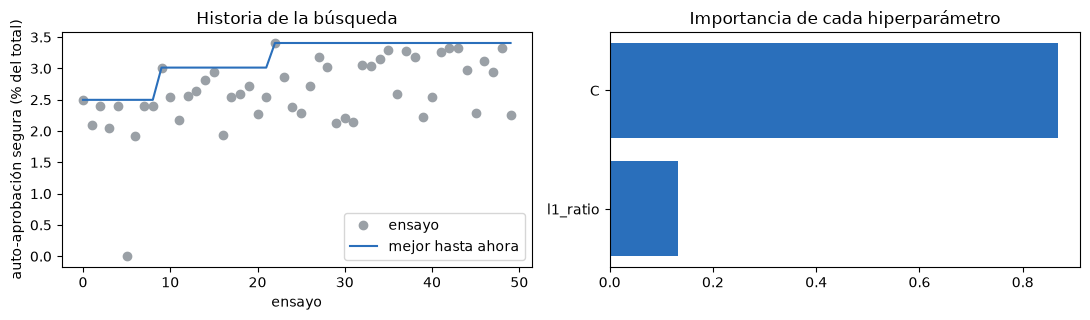

,number,value,user_attrs_roc_auc,user_attrs_pr_auc_deny,params_C,params_l1_ratio
22,22,0.0341,0.7291,0.1824,0.0317,0.3393
42,42,0.0333,0.7290,0.1824,0.0451,0.5068
48,48,0.0333,0.7290,0.1824,0.0453,0.5293
43,43,0.0332,0.7291,0.1823,0.0431,0.4582
35,35,0.0329,0.7291,0.1827,0.0231,0.2691


In [4]:
vals = np.array([t.value for t in study.trials]) * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(vals, "o", color="#9aa0a6", label="ensayo"); axes[0].plot(np.maximum.accumulate(vals), "-", color="#2A6FBB", label="mejor hasta ahora")
axes[0].set_xlabel("ensayo"); axes[0].set_ylabel("auto-aprobación segura (% del total)"); axes[0].legend(); axes[0].set_title("Historia de la búsqueda")
try:
    imp = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
    axes[1].barh(imp.index, imp.values, color="#2A6FBB"); axes[1].set_title("Importancia de cada hiperparámetro")
except Exception as e:                        # p. ej. si todos los ensayos dan el mismo valor
    axes[1].text(0.5, 0.5, f"sin importancias ({type(e).__name__})", ha="center"); axes[1].set_axis_off()
plt.tight_layout(); plt.show()
tdf = study.trials_dataframe()
tdf.sort_values("value", ascending=False).head(5)[["number", "value", "user_attrs_roc_auc", "user_attrs_pr_auc_deny"] + [c for c in tdf.columns if c.startswith("params_")]].round(4)

## 3. Comprobación honesta: ¿optimizar sirvió?

La mejor puntuación de una búsqueda es optimista. Se compara **por defecto** vs **optimizado** con una validación cruzada por gerente **con otra semilla** (otros grupos de gerentes por pliegue). Si la diferencia es menor que lo que varía entre
repeticiones, la mejora **no se distingue del ruido**. Como la auto-aprobación estricta es muy sensible a un solo caso, se muestran también ROC-AUC y PR-AUC.

In [5]:
rows = []
for seed in (7, 11, 23):
    folds_s = fold_matrices(X, y, X[GROUP_COL], make_cv(5, seed), seed=seed)
    for label, params in [("por defecto", None), ("optimizado", HP)]:
        p = oof_predictions(params, folds_s)
        m = metrics_at(y, p)
        rows.append({"semilla": seed, "modelo": label, "AAR @ FPR=0": auto_approval_at_zero_fpr(y, p)["auto_approval_rate"],
                     "ROC-AUC": m["roc_auc"], "PR-AUC denegar": m["pr_auc_deny"]})
chk = pd.DataFrame(rows)
summary_chk = chk.groupby("modelo")[["AAR @ FPR=0", "ROC-AUC", "PR-AUC denegar"]].agg(["mean", "std"])
display(summary_chk.round(4))
piv = chk.pivot(index="semilla", columns="modelo", values="AAR @ FPR=0")
d = piv["optimizado"] - piv["por defecto"]
print(f"Diferencia de auto-aprobación (optimizado − defecto) por semilla: {d.round(5).to_dict()}")
print("Lectura:", "el modelo optimizado auto-aprueba más en todas las semillas" if (d > 0).all()
      else "NO mejora de forma consistente: con estas semillas la optimización no se distingue del ruido; el modelo por defecto es igual de bueno y más simple")

AAR @ FPR=0         ROC-AUC         PR-AUC denegar        
                   mean     std    mean     std           mean     std
modelo                                                                
optimizado       0.0168  0.0058  0.7307  0.0030         0.1877  0.0016
por defecto      0.0150  0.0058  0.7304  0.0017         0.1856  0.0009

Diferencia de auto-aprobación (optimizado − defecto) por semilla: {7: -0.00298, 11: 0.0061, 23: 0.00206}
Lectura: NO mejora de forma consistente: con estas semillas la optimización no se distingue del ruido; el modelo por defecto es igual de bueno y más simple


## 4. Predicciones fuera de pliegue del modelo optimizado y puntos de operación

Dos puntos de operación para auto-aprobar (todo lo demás va a revisión humana):

* **Estricto (FPR = 0 %):** `T_auto` = puntuación del indebido mejor puntuado. Sin accesos indebidos en la validación cruzada.
* **Práctico (confianza ≥ 98 %):** `p ≥ 0,98`. Cubre más, pero deja pasar accesos indebidos.

In [6]:
p_oof = oof_predictions(HP, folds)
m = metrics_at(y, p_oof)
z = auto_approval_at_zero_fpr(y, p_oof)
c = auto_approval_at_confidence(y, p_oof, AUTO_APPROVE_CONFIDENCE)
T_AUTO = z["threshold"]
print(f"OOF · ROC-AUC = {m['roc_auc']:.4f} · PR-AUC denegar = {m['pr_auc_deny']:.4f} (azar = {1 - y.mean():.4f})")
points = pd.DataFrame([
    {"punto de operación": "estricto (FPR = 0 %)", "umbral": T_AUTO, "% auto-aprobado": z["auto_approval_rate"], "n auto-aprobadas": z["n_approved"],
     "accesos indebidos (FP)": 0, "precisión": 1.0, "FPR real ≤ (95 %)": z["fpr_upper95"], "% a revisión": 1 - z["auto_approval_rate"]},
    {"punto de operación": f"práctico (p ≥ {AUTO_APPROVE_CONFIDENCE})", "umbral": AUTO_APPROVE_CONFIDENCE, "% auto-aprobado": c["auto_approval_rate"], "n auto-aprobadas": c["n_approved"],
     "accesos indebidos (FP)": c["fp"], "precisión": c["precision"], "FPR real ≤ (95 %)": c["fpr_upper95"], "% a revisión": 1 - c["auto_approval_rate"]},
]).set_index("punto de operación")
points.round(4)

OOF · ROC-AUC = 0.7291 · PR-AUC denegar = 0.1824 (azar = 0.0579)


,umbral,% auto-aprobado,n auto-aprobadas,accesos indebidos (FP),precisión,FPR real ≤ (95 %),% a revisión
punto de operación,,,,,,,
estricto (FPR = 0 %),0.9809,0.0341,893,0,1.0000,0.002,0.9659
práctico (p ≥ 0.98),0.9800,0.0369,968,4,0.9959,0.006,0.9631


## 5. Triaje asistido: ¿ayuda la cola ordenada al analista?

La cola es todo lo que no supera `T_auto`. Se ordena de **más a menos sospechoso** (p más baja primero). Si el modelo ordena bien, un analista que revise solo el primer X % de la cola encuentra una fracción de las denegaciones **mayor que X %**.
La referencia sin modelo es el azar: revisar el X % al azar encuentra el X % de las denegaciones.

Cola de revisión: 25,322 solicitudes (96.6% del total) · tasa de denegación en la cola 5.99% (global 5.79%) · lift = 1.04


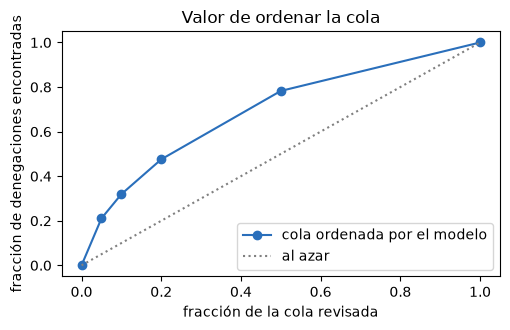

,% de la cola revisado,% de denegaciones encontradas,referencia al azar,mejora sobre el azar (×)
0,5 %,0.211,0.05,4.216
1,10 %,0.319,0.10,3.195
2,20 %,0.476,0.20,2.378
3,50 %,0.783,0.50,1.565


In [7]:
qc = queue_capture(y, p_oof, T_AUTO, fractions=(0.05, 0.10, 0.20, 0.50))
rq = review_queue_stats(y, p_oof, T_AUTO + 1e-12)
fr = [0.05, 0.10, 0.20, 0.50]
cap = pd.DataFrame({"% de la cola revisado": [f"{int(f * 100)} %" for f in fr],
                    "% de denegaciones encontradas": [qc[f"{int(f * 100)}%"] for f in fr],
                    "referencia al azar": fr})
cap["mejora sobre el azar (×)"] = cap["% de denegaciones encontradas"] / cap["referencia al azar"]
print(f"Cola de revisión: {qc['n_queue']:,} solicitudes ({rq['review_rate']:.1%} del total) · tasa de denegación en la cola {rq['deny_rate_in_queue']:.2%} (global {1 - y.mean():.2%}) · lift = {rq['lift']:.2f}")
fig, ax = plt.subplots(figsize=(5.2, 3.4))
xs = np.r_[0, fr, 1.0]; ys = np.r_[0, cap["% de denegaciones encontradas"].to_numpy(), 1.0]
ax.plot(xs, ys, "o-", color="#2A6FBB", label="cola ordenada por el modelo"); ax.plot([0, 1], [0, 1], ":", color="grey", label="al azar")
ax.set_xlabel("fracción de la cola revisada"); ax.set_ylabel("fracción de denegaciones encontradas"); ax.set_title("Valor de ordenar la cola"); ax.legend()
plt.tight_layout(); plt.show()
cap.round(3)

**Lectura.** Si la mejora sobre el azar es cercana a 1×, el modelo **no ayuda a priorizar** y el analista debe revisar casi todo en cualquier orden (riesgo de fatiga de aprobación). Si es claramente > 1×, ordenar la cola reduce el esfuerzo de encontrar los casos riesgosos.

## 6. Sensibilidad del umbral estricto (presupuesto de falsos positivos)

El umbral FPR = 0 % depende de **un único caso**. ¿Cuánto más se auto-aprobaría si se tolerara 1, 2, 5… accesos indebidos en la validación cruzada? Esta tabla reemplaza al antiguo análisis de sensibilidad de costos: muestra la **frontera entre seguridad y cobertura**, sin asignar un precio a cada error.

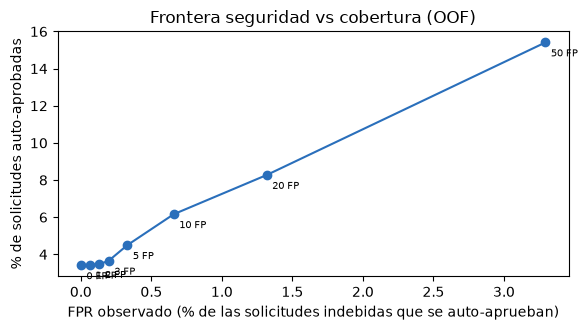

,umbral,% auto-aprobado,n auto-aprobadas,FP reales,FPR,FPR real ≤ (95 %),% a revisión
FP tolerados,,,,,,,
0,0.9809,0.0341,893,0,0.0000,0.0020,0.9659
1,0.9808,0.0344,901,1,0.0007,0.0031,0.9656
2,0.9807,0.0347,910,2,0.0013,0.0041,0.9653
3,0.9801,0.0365,958,3,0.0020,0.0051,0.9635
5,0.9777,0.0449,1178,5,0.0033,0.0069,0.9551
10,0.9733,0.0616,1615,10,0.0066,0.0111,0.9384
20,0.9688,0.0827,2168,20,0.0132,0.0191,0.9173
50,0.9543,0.1541,4039,50,0.0329,0.0415,0.8459


In [8]:
rows = []
for k in [0, 1, 2, 3, 5, 10, 20, 50]:
    b = auto_approval_at_fp_budget(y, p_oof, k)
    rows.append({"FP tolerados": k, "umbral": b["threshold"], "% auto-aprobado": b["auto_approval_rate"], "n auto-aprobadas": b["n_approved"],
                 "FP reales": b["fp"], "FPR": b["fpr"], "FPR real ≤ (95 %)": b["fpr_upper95"], "% a revisión": 1 - b["auto_approval_rate"]})
frontier = pd.DataFrame(rows).set_index("FP tolerados")
frontier.to_csv(REPORTS_DIR / "06_zt_frontera_seguridad.csv")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(frontier["FPR"] * 100, frontier["% auto-aprobado"] * 100, "o-", color="#2A6FBB")
for k, r in frontier.iterrows():
    ax.annotate(f"{k} FP", (r["FPR"] * 100, r["% auto-aprobado"] * 100), textcoords="offset points", xytext=(4, -10), fontsize=7)
ax.set_xlabel("FPR observado (% de las solicitudes indebidas que se auto-aprueban)"); ax.set_ylabel("% de solicitudes auto-aprobadas"); ax.set_title("Frontera seguridad vs cobertura (OOF)")
plt.tight_layout(); plt.show()
frontier.round(4)

## 7. Modelo final y exportación

Se entrena el pipeline completo (`IAMFeatureBuilder` + modelo con los hiperparámetros elegidos) con **todo** el entrenamiento y se guarda un paquete con el pipeline, los umbrales y los metadatos en
**`models/model.joblib`** (el nombre que espera la app) y una copia en **`models/best_model_iam.joblib`**. **Esto reemplaza al modelo del enfoque monetario.**
Para cargarlo hace falta `src/` en el `PYTHONPATH`. Uso: `predict_zero_trust(bundle, X)` (en `accessguard.security_metrics`) → `aprobar_auto` / `revisar` + prioridad en la cola.

> La app de Streamlit actual es la plantilla del curso (módulo `creditsight`, otro caso): sigue necesitando adaptarse a este paquete y a su esquema de entrada.

In [9]:
final_pipe = build_pipeline(MODEL, HP, seed=SEED).fit(X, y)
latency = decision_latency_ms(final_pipe, X, repeats=60)

bundle = {
    "pipeline": final_pipe,
    "t_auto_strict": float(T_AUTO), "t_confidence": float(AUTO_APPROVE_CONFIDENCE),
    "decision_rule": "p=P(aprobar). p > t_auto_strict: aprobar automáticamente; en otro caso: revisión humana ordenada por p ascendente. No se auto-deniega.",
    "framework": "Zero Trust / IGA · Menor Privilegio",
    "model_name": MODEL, "best_params": HP,
    "input_columns": list(X.columns),
    "cv_metrics_oof": {"roc_auc": float(m["roc_auc"]), "pr_auc_deny": float(m["pr_auc_deny"]),
                       "auto_approval_rate_fpr0": float(z["auto_approval_rate"]), "fpr_upper95": float(z["fpr_upper95"]),
                       "scheme": "StratifiedGroupKFold 5 por MGR_ID, semilla 42"},
    "latency_ms": latency,
}
for fname in ("model.joblib", "best_model_iam.joblib"):
    joblib.dump(bundle, MODELS_DIR / fname)

loaded = joblib.load(MODELS_DIR / "model.joblib")
demo = predict_zero_trust(loaded, X.sample(8, random_state=SEED))
print(demo.round(4).to_string())
for fname in ("model.joblib", "best_model_iam.joblib"):
    print(f"{fname}: {(MODELS_DIR / fname).stat().st_size / 1024:.0f} KB")
print("latencia medida:", {k: round(v, 2) for k, v in latency.items()})

(REPORTS_DIR / "06_zt_best_params.json").write_text(json.dumps({
    "model": MODEL, "best_params": HP, "n_trials": N_TRIALS, "objective": "auto_approval_rate @ FPR=0 (OOF, pooled)",
    "t_auto_strict": T_AUTO, "oof": bundle["cv_metrics_oof"], "latency_ms": latency,
}, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
points.to_csv(REPORTS_DIR / "06_zt_puntos_operacion.csv")
cap.to_csv(REPORTS_DIR / "06_zt_captura_cola.csv", index=False)
chk.to_csv(REPORTS_DIR / "06_zt_comprobacion_semillas.csv", index=False)

       p_approve      decision  prioridad_revision
7917      0.9296       revisar                 2.0
20913     0.9905  aprobar_auto                 NaN
22523     0.9998  aprobar_auto                 NaN
18442     0.9999  aprobar_auto                 NaN
1336      1.0000  aprobar_auto                 NaN
24448     0.9920  aprobar_auto                 NaN
7976      0.9999  aprobar_auto                 NaN
17210     0.0000       revisar                 1.0
model.joblib: 8601 KB
best_model_iam.joblib: 8601 KB
latencia medida: {'single_median_ms': 10.56, 'single_p95_ms': 11.73, 'batch_ms_per_request': 0.02}


## 8. Antes de abrir la reserva

> **Aviso de método.** La reserva (`holdout`) **ya se abrió una vez** con el enfoque monetario anterior (resultado archivado en `reports/legacy_costos/`). Aquella evaluación no se usó para elegir nada en este marco,
> pero esta es una **segunda mirada**: queda registrado en el reporte. La reserva real de producción debe seguir siendo `test.csv` con etiquetas reales cuando existan.

Lista de comprobación:

* Modelo, hiperparámetros y `T_auto` fijados con validación cruzada del entrenamiento (secciones 2–6).
* `holdout_features.parquet` se generó en el notebook 04 con transformadores ajustados **solo con el entrenamiento**.
* La reserva son **gerentes que el entrenamiento nunca vio**.
* La celda siguiente **se niega a repetir la evaluación** si ya existe `reports/06_zt_holdout_evaluacion.json`, y se puede desactivar con `OPEN_HOLDOUT = False`.

## 9. Evaluación en la reserva (`Data/processed/holdout_features.parquet`)

In [10]:
OPEN_HOLDOUT = True          # ponlo en False para no abrir la reserva
HOLD_JSON = REPORTS_DIR / "06_zt_holdout_evaluacion.json"

if HOLD_JSON.exists():
    saved = json.loads(HOLD_JSON.read_text(encoding="utf-8"))
    print("La reserva YA se abrió con este marco (", saved["evaluated_at"], "). No se repite; se muestra el resultado guardado.")
    if not (np.isclose(saved["t_auto_strict"], T_AUTO) and saved["model"] == MODEL):
        print("AVISO: el modelo/umbral actuales difieren de los evaluados; el resultado guardado corresponde al modelo anterior.")
elif not OPEN_HOLDOUT:
    saved = None
    print("OPEN_HOLDOUT = False: la reserva permanece cerrada.")
else:
    hold = pd.read_parquet(PROCESSED_DIR / "holdout_features.parquet")
    feat_cols = list(final_pipe.named_steps["features"].feature_names_)
    assert set(feat_cols) <= set(hold.columns), "el parquet de la reserva no tiene las columnas del pipeline"
    assert not set(hold[GROUP_COL]) & set(X[GROUP_COL]), "hay gerentes de la reserva en el entrenamiento"
    yh = hold[TARGET].to_numpy()
    p_h = final_pipe.named_steps["model"].predict_proba(hold[feat_cols])[:, 1]     # el parquet ya trae las variables

    mh = metrics_at(yh, p_h)
    appr = p_h > T_AUTO
    fp_s = int((appr & (yh == 0)).sum()); n_neg_h = int((yh == 0).sum())
    pr = auto_approval_at_confidence(yh, p_h, AUTO_APPROVE_CONFIDENCE)
    qh = queue_capture(yh, p_h, T_AUTO, fractions=(0.05, 0.10, 0.20, 0.50))
    rqh = review_queue_stats(yh, p_h, T_AUTO + 1e-12)
    ref_zero = auto_approval_at_zero_fpr(yh, p_h)                           # lo que habría sido el umbral estricto con los datos de la reserva

    out = {
        "evaluated_at": datetime.datetime.now().isoformat(timespec="seconds"), "model": MODEL, "t_auto_strict": T_AUTO,
        "second_look_note": "la reserva ya se había abierto una vez con el enfoque monetario anterior",
        "n_holdout": int(len(yh)), "n_managers": int(hold[GROUP_COL].nunique()), "n_indebidas": n_neg_h, "pct_indebidas": float(n_neg_h / len(yh)),
        "roc_auc": float(mh["roc_auc"]), "pr_auc_deny": float(mh["pr_auc_deny"]),
        "estricto": {"umbral": T_AUTO, "auto_approval_rate": float(appr.mean()), "n_auto": int(appr.sum()), "fp": fp_s,
                     "fpr": fp_s / max(n_neg_h, 1), "fpr_upper95": fpr_upper_bound(fp_s, n_neg_h), "review_rate": float(1 - appr.mean())},
        "practico_098": {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in pr.items()},
        "umbral_estricto_con_datos_de_la_reserva": {"umbral": ref_zero["threshold"], "auto_approval_rate": ref_zero["auto_approval_rate"]},
        "cola": {"lift": float(rqh["lift"]), "deny_rate_in_queue": float(rqh["deny_rate_in_queue"]), "n_queue": qh["n_queue"],
                 "captura": {k: v for k, v in qh.items() if k != "n_queue"}},
        "baselines": {"revisar todo": {"auto_approval_rate": 0.0, "fp": 0, "review_rate": 1.0},
                      "aprobar todo": {"auto_approval_rate": 1.0, "fp": n_neg_h, "review_rate": 0.0}},
    }
    HOLD_JSON.write_text(json.dumps(out, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
    saved = out
    e = out["estricto"]
    print(f"RESERVA ({len(yh):,} solicitudes, {out['n_managers']} gerentes nuevos, {n_neg_h} indebidas) · ROC-AUC = {mh['roc_auc']:.4f} · PR-AUC denegar = {mh['pr_auc_deny']:.4f} (azar = {n_neg_h / len(yh):.4f})")
    print(f"ESTRICTO (T_auto = {T_AUTO:.4f} fijado en validación): auto-aprobado {e['auto_approval_rate']:.2%} · accesos indebidos concedidos = {e['fp']} · FPR real ≤ {e['fpr_upper95']:.2%}")
    print(f"PRÁCTICO (p ≥ {AUTO_APPROVE_CONFIDENCE}): auto-aprobado {pr['auto_approval_rate']:.2%} · accesos indebidos = {pr['fp']} · precisión {pr['precision']:.2%}")
    print("Lectura:", "el umbral estricto se sostuvo en la reserva (0 accesos indebidos)" if fp_s == 0
          else f"el umbral estricto NO se sostuvo: {fp_s} accesos indebidos se auto-aprobarían. FPR = 0 % en validación no garantiza FPR = 0 % en datos nuevos")

RESERVA (6,554 solicitudes, 883 gerentes nuevos, 379 indebidas) · ROC-AUC = 0.7009 · PR-AUC denegar = 0.1987 (azar = 0.0578)
ESTRICTO (T_auto = 0.9809 fijado en validación): auto-aprobado 5.20% · accesos indebidos concedidos = 2 · FPR real ≤ 1.65%
PRÁCTICO (p ≥ 0.98): auto-aprobado 5.72% · accesos indebidos = 3 · precisión 99.20%
Lectura: el umbral estricto NO se sostuvo: 2 accesos indebidos se auto-aprobarían. FPR = 0 % en validación no garantiza FPR = 0 % en datos nuevos


In [11]:
if saved is not None:
    e, pr_, cq = saved["estricto"], saved["practico_098"], saved["cola"]
    lines = [
        "# Evaluación en la reserva (holdout) — política Zero Trust de auto-aprobación", "",
        f"- Modelo: **{saved['model']}** · reserva: {saved['n_holdout']:,} solicitudes de {saved['n_managers']} gerentes que el entrenamiento nunca vio ({saved['n_indebidas']} indebidas, {saved['pct_indebidas']:.1%}).",
        f"- Evaluada el {saved['evaluated_at']}. **Nota:** {saved['second_look_note']}.",
        f"- Ranking: ROC-AUC = {saved['roc_auc']:.3f} · PR-AUC de denegar = {saved['pr_auc_deny']:.3f} (azar = {saved['pct_indebidas']:.3f}).", "",
        "| Política | % auto-aprobado | Accesos indebidos concedidos | FPR (real ≤ 95 %) | % a revisión humana |", "|---|---|---|---|---|",
        f"| Revisar todo (referencia) | 0,00 % | 0 | 0 % | 100 % |",
        f"| Aprobar todo (referencia) | 100 % | {saved['baselines']['aprobar todo']['fp']} | 100 % | 0 % |",
        f"| **Estricto** (T_auto = {saved['t_auto_strict']:.4f}, fijado en validación cruzada) | {e['auto_approval_rate']:.2%} | {e['fp']} | {e['fpr']:.2%} (≤ {e['fpr_upper95']:.2%}) | {e['review_rate']:.1%} |",
        f"| Práctico (p ≥ {AUTO_APPROVE_CONFIDENCE}) | {pr_['auto_approval_rate']:.2%} | {pr_['fp']} | {pr_['fpr']:.2%} (≤ {pr_['fpr_upper95']:.2%}) | {1 - pr_['auto_approval_rate']:.1%} |", "",
        f"- Cola de revisión: {cq['n_queue']:,} solicitudes; lift = {cq['lift']:.2f}. Denegaciones encontradas revisando solo el primer 10 % de la cola: {cq['captura']['10%']:.1%}; el primer 20 %: {cq['captura']['20%']:.1%} (al azar: 10 % y 20 %).", "",
        ("**Conclusión:** el umbral estricto se sostuvo en la reserva (0 accesos indebidos), con la cota de FPR indicada. Esto no garantiza FPR = 0 % en producción." if e["fp"] == 0
         else f"**Conclusión:** el umbral estricto NO se sostuvo ({e['fp']} accesos indebidos auto-aprobados en la reserva). El FPR = 0 % de la validación cruzada no se generalizó; hace falta un margen de seguridad más amplio (umbral más alto) o un control adicional antes de auto-aprobar."),
    ]
    (REPORTS_DIR / "06_zt_holdout_reporte.md").write_text("\n".join(lines), encoding="utf-8")
    print("\n".join(lines))

# Evaluación en la reserva (holdout) — política Zero Trust de auto-aprobación

- Modelo: **LogReg ElasticNet** · reserva: 6,554 solicitudes de 883 gerentes que el entrenamiento nunca vio (379 indebidas, 5.8%).
- Evaluada el 2026-11-03T18:08:29. **Nota:** la reserva ya se había abierto una vez con el enfoque monetario anterior.
- Ranking: ROC-AUC = 0.701 · PR-AUC de denegar = 0.199 (azar = 0.058).

| Política | % auto-aprobado | Accesos indebidos concedidos | FPR (real ≤ 95 %) | % a revisión humana |
|---|---|---|---|---|
| Revisar todo (referencia) | 0,00 % | 0 | 0 % | 100 % |
| Aprobar todo (referencia) | 100 % | 379 | 100 % | 0 % |
| **Estricto** (T_auto = 0.9809, fijado en validación cruzada) | 5.20% | 2 | 0.53% (≤ 1.65%) | 94.8% |
| Práctico (p ≥ 0.98) | 5.72% | 3.0 | 0.79% (≤ 2.03%) | 94.3% |

- Cola de revisión: 6,213 solicitudes; lift = 1.05. Denegaciones encontradas revisando solo el primer 10 % de la cola: 30.6%; el primer 20 %: 41.7% (al azar: 10 % y 20 %).

**Conclusión:** e

## 10. Qué concluir (y qué no)

* El **valor del modelo** se mide con la Tasa de Auto-Aprobación Segura de la reserva (sección 9), no con la de validación cruzada, que es optimista. Compárala siempre con "revisar todo" (0 % auto-aprobado, 0 accesos indebidos): el modelo solo aporta si auto-aprueba una fracción útil **sin** accesos indebidos.
* El umbral estricto es **frágil** (depende de un solo caso). La frontera de la sección 6 muestra cuánta cobertura se gana al tolerar más accesos indebidos; esa tolerancia es una **decisión de riesgo de Seguridad/Cumplimiento**, no del modelo.
* **0 accesos indebidos observados ≠ 0 reales:** toda cifra va con su cota superior al 95 %.
* La cola ordenada solo reduce la fatiga de aprobación si la captura de denegaciones supera claramente al azar (sección 5).
* **Siguen faltando datos:** el SLA manual real (tiempos de tickets) y la criticidad de cada recurso. Con la criticidad se podrían fijar **umbrales por recurso** (más estricto en recursos críticos, más laxo en los de bajo riesgo).
* Debe haber controles adicionales para una auto-aprobación real: detección de anomalías, re-certificación periódica de accesos y registro de auditoría de cada decisión.
* Pendiente: interpretación de variables (SHAP) y adaptar la app de Streamlit al paquete `model.joblib`.